# Experiment 29: VAE/GAN Sample Generation

A fashion retailer wants to prototype grayscale product images. We train a compact variational autoencoder and a DCGAN on Fashion-MNIST, generate latent samples, visualise the VAE's two-dimensional latent grid and save GAN snapshots after each epoch.

**Tools:** TensorFlow, Keras, NumPy, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Build and train a VAE with encoder, reparameterisation and decoder using reconstruction plus KL loss.  2. Generate samples and plot a 2-D latent grid.  3. Build a DCGAN generator and discriminator.  4. Train the GAN and capture generated images each epoch.  5. Plot generator and discriminator loss curves.

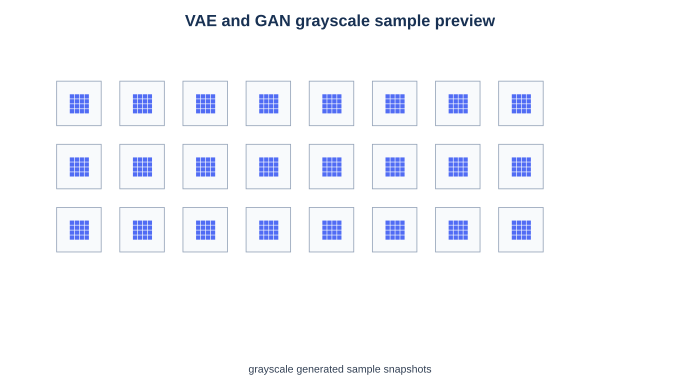

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

tf.keras.utils.set_random_seed(29)
(x_train,_),(x_test,y_test)=tf.keras.datasets.fashion_mnist.load_data()
x_train=x_train[:6000].astype("float32")/127.5-1.
fashion_eval=x_test[:2000].astype("float32")/127.5-1.
fashion_labels=y_test[:2000]
train_ds=tf.data.Dataset.from_tensor_slices(x_train[...,None]).shuffle(6000).batch(128)

latent_dim=2
class Sampling(tf.keras.layers.Layer):
    def call(self,inputs):
        mean,logvar=inputs
        eps=tf.random.normal(tf.shape(mean))
        return mean+tf.exp(.5*logvar)*eps
enc_in=tf.keras.Input((28,28,1))
q=tf.keras.layers.Flatten()(enc_in)
q=tf.keras.layers.Dense(256,activation="relu")(q)
z_mean=tf.keras.layers.Dense(latent_dim)(q)
z_logvar=tf.keras.layers.Dense(latent_dim)(q)
z=Sampling()([z_mean,z_logvar])
encoder=tf.keras.Model(enc_in,[z_mean,z_logvar,z],name="encoder")
dec_in=tf.keras.Input((latent_dim,))
d=tf.keras.layers.Dense(256,activation="relu")(dec_in)
d=tf.keras.layers.Dense(784,activation="tanh")(d)
dec_out=tf.keras.layers.Reshape((28,28,1))(d)
decoder=tf.keras.Model(dec_in,dec_out,name="decoder")
class VAE(tf.keras.Model):
    def __init__(self,encoder,decoder):
        super().__init__();self.encoder=encoder;self.decoder=decoder;self.loss_tracker=tf.keras.metrics.Mean(name="loss")
    @property
    def metrics(self):return [self.loss_tracker]
    def train_step(self,data):
        x=data[0] if isinstance(data,(tuple,list)) else data
        with tf.GradientTape() as tape:
            mean,logvar,z=self.encoder(x,training=True)
            recon=self.decoder(z,training=True)
            rec=tf.reduce_mean(tf.reduce_sum(tf.square(x-recon),axis=(1,2,3)))
            kl=-.5*tf.reduce_mean(tf.reduce_sum(1+logvar-tf.square(mean)-tf.exp(logvar),axis=1))
            loss=rec+kl
        grads=tape.gradient(loss,self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads,self.trainable_variables))
        self.loss_tracker.update_state(loss);return {"loss":self.loss_tracker.result()}
vae=VAE(encoder,decoder);vae.compile(optimizer=tf.keras.optimizers.Adam())
vae_history=vae.fit(train_ds,epochs=4,verbose=0)

# Sample a regular grid in the 2-D latent space.
grid_axis=np.linspace(-2.5,2.5,12)
latent_grid=np.array([[a,b] for b in grid_axis for a in grid_axis],dtype="float32")
grid_images=decoder.predict(latent_grid,verbose=0)
fig,axes=plt.subplots(6,6,figsize=(6,6))
for ax,img in zip(axes.flat,grid_images[::4]):ax.imshow(img.squeeze(),cmap="gray",vmin=-1,vmax=1);ax.axis("off")
plt.suptitle("VAE latent-space sample grid");plt.tight_layout();plt.show()

# DCGAN with explicit gradient updates; snapshots are kept in memory for this notebook.
generator=tf.keras.Sequential([tf.keras.layers.Input((64,)),
    tf.keras.layers.Dense(7*7*128,use_bias=False),tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(.2),tf.keras.layers.Reshape((7,7,128)),
    tf.keras.layers.Conv2DTranspose(64,4,strides=2,padding="same",use_bias=False),
    tf.keras.layers.BatchNormalization(),tf.keras.layers.LeakyReLU(.2),
    tf.keras.layers.Conv2DTranspose(1,4,strides=2,padding="same",activation="tanh")])
discriminator=tf.keras.Sequential([tf.keras.layers.Input((28,28,1)),
    tf.keras.layers.Conv2D(64,4,strides=2,padding="same"),tf.keras.layers.LeakyReLU(.2),
    tf.keras.layers.Dropout(.3),tf.keras.layers.Conv2D(128,4,strides=2,padding="same"),
    tf.keras.layers.LeakyReLU(.2),tf.keras.layers.Flatten(),tf.keras.layers.Dense(1)])
g_opt=tf.keras.optimizers.Adam(1e-4,beta_1=.5);d_opt=tf.keras.optimizers.Adam(1e-4,beta_1=.5)
bce=tf.keras.losses.BinaryCrossentropy(from_logits=True)
g_losses=[];d_losses=[];gan_snapshots=[]
for epoch in range(4):
    for real in train_ds:
        bs=tf.shape(real)[0];noise=tf.random.normal((bs,64))
        with tf.GradientTape() as dt,tf.GradientTape() as gt:
            fake=generator(noise,training=True)
            real_logits=discriminator(real,training=True)
            fake_logits=discriminator(fake,training=True)
            dloss=bce(tf.ones_like(real_logits),real_logits)+bce(tf.zeros_like(fake_logits),fake_logits)
            gloss=bce(tf.ones_like(fake_logits),fake_logits)
        d_grads=dt.gradient(dloss,discriminator.trainable_variables)
        g_grads=gt.gradient(gloss,generator.trainable_variables)
        d_opt.apply_gradients(zip(d_grads,discriminator.trainable_variables))
        g_opt.apply_gradients(zip(g_grads,generator.trainable_variables))
        d_losses.append(float(dloss));g_losses.append(float(gloss))
    gan_snapshots.append(generator(tf.random.normal((16,64)),training=False).numpy())
    print(f"epoch {epoch+1}: generator loss={np.mean(g_losses[-len(train_ds):]):.3f}, discriminator loss={np.mean(d_losses[-len(train_ds):]):.3f}")
# Save the two generators so Experiment 30 can run in a separate notebook.
decoder.save("Exp29_vae_decoder.keras")
generator.save("Exp29_gan_generator.keras")
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].plot(vae_history.history["loss"]);axes[0].set(title="VAE total loss",xlabel="Epoch")
axes[1].plot(g_losses,label="generator");axes[1].plot(d_losses,label="discriminator")
axes[1].set(title="DCGAN losses",xlabel="Update");axes[1].legend()
for ax in axes:ax.grid(alpha=.2)
plt.tight_layout();plt.show()
fig,axes=plt.subplots(4,4,figsize=(5,5))
for ax,img in zip(axes.flat,gan_snapshots[-1]):ax.imshow(img.squeeze(),cmap="gray",vmin=-1,vmax=1);ax.axis("off")
plt.suptitle("Latest GAN samples");plt.tight_layout();plt.show()